Loading weights: 100%|██████████| 148/148 [00:00<00:00, 5047.83it/s]


(50257, 768)


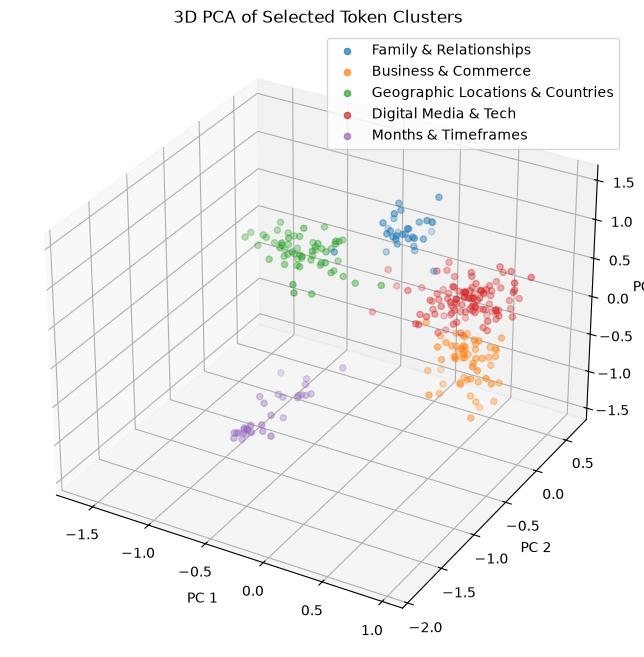

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 4213.06it/s]


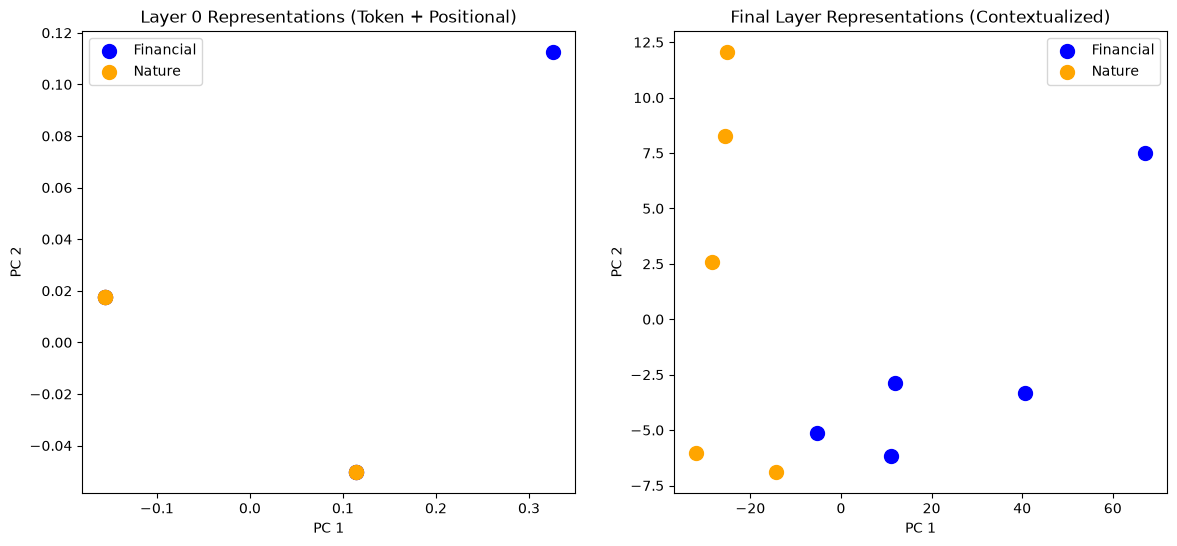

Cluster 1: [' friend', ' mom', ' friends', ' parent', ' mother', ' father', ' son', ' parents', ' wife', ' brother', ' favorite', ' neighbor', ' partners', ' daughter', ' partner']

Cluster 5: [' business', ' rese', ' company', ' product', ' market', ' sold', ' companies', ' price', ' buy', ' industry', ' purch', ' products', ' trade', ' store', ' sell']

Cluster 12: [' wor', ' whe', ' bec', ' spe', ' att', ' pol', ' sec', ' supp', ' bu', ' diff', ' sy', ' prov', ' pres', ' inst', ' hel']

Cluster 18: [' Euro', ' Europe', ' Brit', ' countries', ' German', ' China', ' Japan', ' Austral', ' international', ' Russia', ' Canada', ' Russian', ' European', ' UK', ' British']

Cluster 25: [' soc', ' social', ' Soc', ' psych', ' Social', ' Psych', 'ocial']

Cluster 32: [' produ', ' indust', ' production', 'ufact', ' manufact', ' manufacture', ' industrial', ' factory', ' agric', ' Indust', ' manufacturing', 'actory']

Cluster 45: [' very', ' many', ' long', ' own', ' same', ' world', ' high', 

In [2]:
import torch
from transformers import GPT2Model, GPT2Tokenizer
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

model_name = "gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(model_name)
model = GPT2Model.from_pretrained(model_name)

model.eval()

with torch.no_grad():
    static_embeddings = model.wte.weight.numpy()

print(static_embeddings.shape)


tokens_subset = static_embeddings[:10000]

kmeans = KMeans(n_clusters=100, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(tokens_subset)

selected_clusters = [1, 5, 18, 55, 72]

cluster_titles = {
    1: "Family & Relationships",
    5: "Business & Commerce",
    18: "Geographic Locations & Countries",
    55: "Digital Media & Tech",
    72: "Months & Timeframes"
}

mask = np.isin(cluster_labels, selected_clusters)
filtered_embeddings = tokens_subset[mask]
filtered_labels = cluster_labels[mask]

pca = PCA(n_components=3)
embeddings_3d = pca.fit_transform(filtered_embeddings)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

for cluster_id in selected_clusters:
    cluster_mask = (filtered_labels == cluster_id)
    ax.scatter(
        embeddings_3d[cluster_mask, 0],
        embeddings_3d[cluster_mask, 1],
        embeddings_3d[cluster_mask, 2],
        label=cluster_titles[cluster_id],
        alpha=0.7
    )

ax.set_title("3D PCA of Selected Token Clusters")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_zlabel("PC 3")
ax.legend()
plt.show()

model = GPT2Model.from_pretrained("gpt2", output_hidden_states=True)
model.eval()

financial_sentences = [
    "I need to deposit my money in the bank",
    "She went to open a new account at the bank",
    "The government decided to regulate every commercial bank",
    "He borrowed some money from a local bank",
    "They Wall Street firm is a very large bank"
]

nature_sentences = [
    "We sat down to rest on the river bank",
    "The green grass grows along the muddy bank",
    "Water overflowed and flooded the eastern bank",
    "The boat safely anchored near the rocky bank",
    "Birds built their nests on the steep bank"
]

all_sentences = financial_sentences + nature_sentences
labels = ["Financial"] * 5 + ["Nature"] * 5

layer_0_reps = []
final_layer_reps = []

for sentence in all_sentences:
    inputs = tokenizer(sentence, return_tensors="pt")
    
    with torch.no_grad():
        outputs = model(**inputs)
    
    l0 = outputs.hidden_states[0][0, -1, :].numpy()
    lf = outputs.hidden_states[-1][0, -1, :].numpy()
    
    layer_0_reps.append(l0)
    final_layer_reps.append(lf)

layer_0_reps = np.array(layer_0_reps)
final_layer_reps = np.array(final_layer_reps)

pca_0 = PCA(n_components=2).fit_transform(layer_0_reps)
pca_f = PCA(n_components=2).fit_transform(final_layer_reps)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
colors = ['blue' if l == "Financial" else 'orange' for l in labels]

for style, label_type in [('blue', 'Financial'), ('orange', 'Nature')]:
    idx = [i for i, l in enumerate(labels) if l == label_type]
    ax1.scatter(pca_0[idx, 0], pca_0[idx, 1], c=style, label=label_type, s=100)
ax1.set_title("Layer 0 Representations (Token + Positional)")
ax1.set_xlabel("PC 1")
ax1.set_ylabel("PC 2")
ax1.legend()

for style, label_type in [('blue', 'Financial'), ('orange', 'Nature')]:
    idx = [i for i, l in enumerate(labels) if l == label_type]
    ax2.scatter(pca_f[idx, 0], pca_f[idx, 1], c=style, label=label_type, s=100)
ax2.set_title("Final Layer Representations (Contextualized)")
ax2.set_xlabel("PC 1")
ax2.set_ylabel("PC 2")
ax2.legend()

plt.show()
